# **TP2 - Bivariate Analysis**

<b>Exploratory Data Analysis & Unsuperivsed Learning </b><br>
**Course: Dr. HAS Sothea** <br> 
**TP: Dr. Ms. UANN Sreyvi**

-------

**Objective**: To equip you all with the skills to analyze and interpret the relationship between two variables. You will explore these relationships as a function of time using the [`Gapminder`](https://pypi.org/project/gapminder/) dataset.

---------

> **The `Jupyter Notebook` for this TP can be downloaded here: [TP2-Bivariate-Gapminder](https://hassothea.github.io/M1_DAS_EDA_ITC/TPs/TP2_Bivariate_Analysis.ipynb)**.

-------

In [2]:
#| warning: false
#%pip install gapminder           # This is for installing the package
from gapminder import gapminder
import pandas as pd
import numpy as np
import plotly.io as pio
pio.renderers.default = 'notebook'
gapminder.head()

,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106


# **1. Pearson and Spearman's correlations**

**a.** Compute Pearson correlation matrix of the three quantitative variables on year $1952$, $1987$ and then $2007$ using `pd.corr()`. Give a brief intuition of the relationship between these variables.

In [ ]:
# Year 1952
data1952 = gapminder[gapminder['year'] == 1952]
quan_vars = ['lifeExp', 'pop', 'gdpPercap']     # Create a list of quantitative variables
corr_person_1952 =data1952[quan_vars].corr(method='pearson')      # Compute the correlation matrix for the quantitative variables in 1952
corr_person_1952.style.background_gradient(cmap='coolwarm')


,lifeExp,pop,gdpPercap
lifeExp,1.000000,-0.002725,0.278024
pop,-0.002725,1.000000,-0.025260
gdpPercap,0.278024,-0.025260,1.000000


In [ ]:
# Year 1987
data1987 = gapminder[gapminder['year'] == 1987]
corr_person_1987 = data1987[quan_vars].corr(method='pearson')      # Compute the correlation matrix for the quantitative variables in 1987
corr_person_1987.style.background_gradient(cmap='coolwarm')

,lifeExp,pop,gdpPercap
lifeExp,1.000000,0.033062,0.749905
pop,0.033062,1.000000,-0.051705
gdpPercap,0.749905,-0.051705,1.000000


In [9]:
# Year 2007
data2007 = gapminder[gapminder['year'] == 2007]
corr_person_2007 = data2007[quan_vars].corr(method='pearson')
corr_person_2007.style.background_gradient(cmap='cool')

,lifeExp,pop,gdpPercap
lifeExp,1.000000,0.047553,0.678662
pop,0.047553,1.000000,-0.055676
gdpPercap,0.678662,-0.055676,1.000000


In [ ]:
# Use Query to filter the data for each year and compute the correlation matrix for the quantitative variables in that year.
# year 2007
data2007 = gapminder.query('year == 2007')
corr_person_2007 = data2007[quan_vars].corr(method='pearson')
corr_person_2007.style.background_gradient(cmap='hot')

,lifeExp,pop,gdpPercap
lifeExp,1.000000,0.047553,0.678662
pop,0.047553,1.000000,-0.055676
gdpPercap,0.678662,-0.055676,1.000000


**Description:** 
- In 1952, 1987, and 2007, we can see that the pearson correlation between `pop` and both `gdpPercap` as well as `lifeExp` are quite insignificant. This seems to indicate that poppulation is not linearly to neither economic nor health. 
- On the other hand, `lifeExp` and `gdpPercap` seem to be linear related in 1987 and 2007 but not so sinigicant back 

-----

**b.** Compute Spearman's Rank Correlation of the previous columns in 1952, 1987 and 2007. What do you observe?

In [11]:
# Year 1952
corr_spearman_1952 =data1952[quan_vars].corr(method='spearman')      # Compute the correlation matrix for the quantitative variables in 1952
corr_spearman_1952.style.background_gradient(cmap='coolwarm')

,lifeExp,pop,gdpPercap
lifeExp,1.000000,0.175466,0.768701
pop,0.175466,1.000000,0.086571
gdpPercap,0.768701,0.086571,1.000000


In [12]:
# Year 1987
corr_spearman_1987 = data1987[quan_vars].corr(method='spearman')
corr_spearman_1952.style.background_gradient(cmap='hot')

,lifeExp,pop,gdpPercap
lifeExp,1.000000,0.175466,0.768701
pop,0.175466,1.000000,0.086571
gdpPercap,0.768701,0.086571,1.000000


In [13]:
# Year 2007
corr_spearman_2007 = data1987[quan_vars].corr(method='spearman')
corr_spearman_2007.style.background_gradient(cmap='summer')

,lifeExp,pop,gdpPercap
lifeExp,1.000000,0.053419,0.892465
pop,0.053419,1.000000,0.008355
gdpPercap,0.892465,0.008355,1.000000


**c.** From the previous result, pick the most interesting pair of variables and plot a graph illustrating their relationship on each year, using proper axis scaling and title.

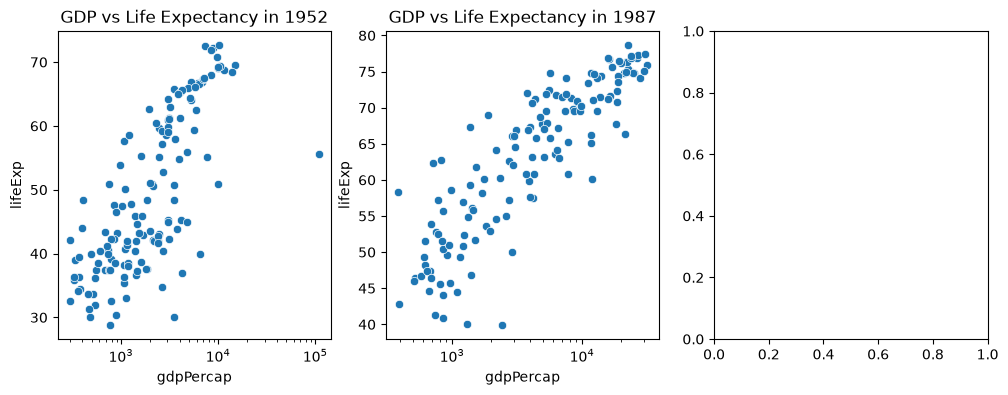

In [17]:
import seaborn as sns # create graph
import matplotlib.pyplot as plt # manage window of graph
fig, axes = plt.subplots(1,3, figsize=(12, 4)) # break window in to 1 row and 3 columns

# fig 1
sns.scatterplot( # choose graphic type
    data1952,    # give data
    x = 'gdpPercap',  # choose variable
    y = 'lifeExp',     # choose variable
    ax=axes[0]
)
axes[0].set_title("GDP vs Life Expectancy in 1952")
axes[0].set_xscale('log')

# fig 2
sns.scatterplot( # choose graphic type
    data1987,    # give data
    x = 'gdpPercap',  # choose variable
    y = 'lifeExp',     # choose variable
    ax=axes[1]
)
axes[1].set_title("GDP vs Life Expectancy in 1987")
axes[1].set_xscale('log')
plt.show()

**d.** Revisit your intuition of the correlation matrix in year 1952 from question **(a)**, can you see why we observed such a (poor) correlation in 1952?!


----

> **Remark:** Pearson correlation matrix can summarize linear relationship between pairs of quantitative variables but it might be inacurate and influenced by 

> - outliers, 
> - non-linearity, 
> - small sample size, 
> - confounding (causal) variables...

**Conclusion:** 

----

# **2. Visualization with more information**

`Scatterplot` is the primary graphic type for visualizing the relationship between two quantitative variables. Additionally, you can include other factors of interest using color, shape, size, facets, etc., depending on the type of those variables. 

------------

The following questions apply to the years 1952, 1987, and 2007:

**a.** Do you think health conditions and economies differ across continents? Compute some indicators to illustrate this.

In [5]:
# To do

> Description: 

**c.** We will try to confirm this using Analysis of Variance (ANOVA). 

In 2007,

- Perform one way ANOVA on `lifeExp` and `continent` (you can use `f_oneway` from `scipy.stats` module).

In [6]:
# To do

- Do the same with `gdpPercap` and `continent`.

- Are these results reliable? Why?

> Your response: 

- Propose ideas that might solve this problem or an alternative method.

> Your response: 

**d.** We have previously described the relationship between population and life expectancy or GDP per capita. Now, illustrate the effect of population defining **size** of points according to variable `pop`.

In [7]:
# To do

**e.** Now, directly visualize the relation between `pop` and `lifeExp`, then the relation between `pop` and `gdpPercap`. Explain the resulting graphs.

In [8]:
# To do

# **3. Quantitative vs Qualitative**

**a.** We have seen how life expectancy and economy vary across continents in 2007 ([Slide 25 of the course](https://hassothea.github.io/EDA_ITC/Slides/Bivariate_Analysis.html#/quan.-vs-qual.-3)). Compute $\eta$-squared correlation between `continent` and `lifeExp`, then `continent` with `gdpPercap` in 1952, 1987 and 2007. 

- Do you find the results reasonable? 

In [9]:
# To do

# **4. Time evolution**

**a.** Draw the evolution of the following correaltions from 1952 to 2007:

- `Person` and `Spearman` corerlation between life expectancy and GDP per capita
- $\eta$-squared coefficients of continent vs life expectancy, and continents vs GDP per capita.

> Hint: the following figure is expected. 

![](./corrs.png)

In [10]:
import plotly.io as pio
pio.renderers.default = 'notebook'
import plotly.express as px

# To do

**b.** Compare side by side the three aspects: population, life expectancy and GDP per Capita between Cambodia and Thailand from 1952 to 2007.

In [11]:
# To do

**c.** Describe what you observed: the world from 1952 to 2007.

> Description: 

# Further readings
- Gapminder documentation: [https://www.gapminder.org/data/documentation/](https://www.gapminder.org/data/documentation/)
- A short demonstration video is available here: [Hans Rosling's 200 Countries, 200 Years, 4 Minutes - The Joy of Stats - BBC Four](https://youtu.be/jbkSRLYSojo?si=qipg08VIi999hEgo).
- Graphical tools:
    - [`matplotlib`](https://matplotlib.org/stable/index.html)
    - [`seaborn`](https://seaborn.pydata.org/)
    - [`plotly`](https://plotly.com/python/)